# BÀI THỰC HÀNH 2.4: XÂY DỰNG, TRỰC QUAN HÓA, KIỂM THỬ VÀ TINH CHỈNH CÂY QUYẾT ĐỊNH VỚI WINE DATASET
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


### Khởi tạo, cấu hình Graphviz PATH và nạp các thư viện cần thiết


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for g_path in [r"C:\Program Files\Graphviz\bin", r"C:\Program Files (x86)\Graphviz\bin"]:
    if os.path.exists(g_path) and g_path not in os.environ['PATH']:
        os.environ['PATH'] = g_path + os.pathsep + os.environ['PATH']

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, export_graphviz
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
import graphviz

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Import các thư viện và cấu hình môi trường thành công!")


Import các thư viện và cấu hình môi trường thành công!


## 1. Nạp dữ liệu Wine vào bộ nhớ và hiển thị thông tin về số thuộc tính (dimensionality), số objects (size)


In [2]:
wine = load_wine()
X, y = wine.data, wine.target
feature_names, target_names = wine.feature_names, wine.target_names
n_objects, n_features = X.shape

print("=== THÔNG TIN TẬP DỮ LIỆU CÁC LOẠI RƯỢU (WINE DATASET) ===")
print(f"Số lượng objects (Size / Số mẫu):        {n_objects} mẫu dữ liệu")
print(f"Số lượng thuộc tính (Dimensionality):    {n_features} thuộc tính hóa học")
print(f"Kích thước ma trận đặc trưng X:          {X.shape}")
for i, feat in enumerate(feature_names, 1):
    print(f"   {i:<2}. {feat}")

df_features = pd.DataFrame(X, columns=feature_names)
print("\n=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ĐẶC TRƯNG ===")
print(df_features.head())


=== THÔNG TIN TẬP DỮ LIỆU CÁC LOẠI RƯỢU (WINE DATASET) ===
Số lượng objects (Size / Số mẫu):        178 mẫu dữ liệu
Số lượng thuộc tính (Dimensionality):    13 thuộc tính hóa học
Kích thước ma trận đặc trưng X:          (178, 13)
   1 . alcohol
   2 . malic_acid
   3 . ash
   4 . alcalinity_of_ash
   5 . magnesium
   6 . total_phenols
   7 . flavanoids
   8 . nonflavanoid_phenols
   9 . proanthocyanins
   10. color_intensity
   11. hue
   12. od280/od315_of_diluted_wines
   13. proline

=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ĐẶC TRƯNG ===
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   


## 2. Đặt nhãn (label) cho dữ liệu đã nạp và hiển thị số lớp (classes)


In [3]:
classes, class_counts = np.unique(y, return_counts=True)
print("=== THÔNG TIN NHÃN VÀ CÁC LỚP ===")
print(f"Số lượng lớp phân loại (Number of Classes): {len(classes)} lớp")
for c, name, count in zip(classes, target_names, class_counts):
    print(f"   - Lớp {c} ({name:<10}): {count} mẫu ({count/len(y)*100:.1f}%)")


=== THÔNG TIN NHÃN VÀ CÁC LỚP ===
Số lượng lớp phân loại (Number of Classes): 3 lớp
   - Lớp 0 (class_0   ): 59 mẫu (33.1%)
   - Lớp 1 (class_1   ): 71 mẫu (39.9%)
   - Lớp 2 (class_2   ): 48 mẫu (27.0%)


## 3. Tách dữ liệu thành 70% Training data và 30% Test data


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("=== KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU ===")
print(f"Số mẫu tập Huấn luyện (Training): {len(X_train)} mẫu (70%) | Shape: {X_train.shape}")
print(f"Số mẫu tập Kiểm thử (Testing):    {len(X_test)} mẫu (30%)  | Shape: {X_test.shape}")


=== KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU ===
Số mẫu tập Huấn luyện (Training): 124 mẫu (70%) | Shape: (124, 13)
Số mẫu tập Kiểm thử (Testing):    54 mẫu (30%)  | Shape: (54, 13)


## 4. Chuẩn hóa dữ liệu với StandardScaler


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=== KẾT QUẢ CHUẨN HÓA DỮ LIỆU ===")
print("Mean sau chuẩn hóa (Train):", X_train_scaled.mean(axis=0).round(4))
print("Std sau chuẩn hóa (Train): ", X_train_scaled.std(axis=0).round(4))


=== KẾT QUẢ CHUẨN HÓA DỮ LIỆU ===
Mean sau chuẩn hóa (Train): [ 0.  0.  0.  0. -0.  0.  0. -0.  0. -0.  0.  0. -0.]
Std sau chuẩn hóa (Train):  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Tạo và huấn luyện mô hình DecisionTreeClassifier mặc định (Baseline Model)


In [6]:
clf_base = DecisionTreeClassifier(criterion='gini', random_state=42)
clf_base.fit(X_train_scaled, y_train)

base_train_acc = clf_base.score(X_train_scaled, y_train)
print("=== MÔ HÌNH DECISION TREE CLASSIFIER MẶC ĐỊNH ĐÃ HUẤN LUYỆN THÀNH CÔNG ===")
print(f"Thuật toán:                  CART")
print(f"Độ sâu của cây (Max Depth):  {clf_base.get_depth()} tầng")
print(f"Tổng số nút lá:              {clf_base.get_n_leaves()} lá")
print(f"Độ chính xác trên tập TRAIN: {base_train_acc * 100:.2f}% ({base_train_acc:.4f})  <-- Học thuộc lòng 100%")


=== MÔ HÌNH DECISION TREE CLASSIFIER MẶC ĐỊNH ĐÃ HUẤN LUYỆN THÀNH CÔNG ===
Thuật toán:                  CART
Độ sâu của cây (Max Depth):  4 tầng
Tổng số nút lá:              8 lá
Độ chính xác trên tập TRAIN: 100.00% (1.0000)  <-- Học thuộc lòng 100%


## 6. Test và đánh giá độ chính xác của mô hình mặc định (Confusion Matrix, Accuracy, F-score)


=== ĐÁNH GIÁ MÔ HÌNH MẶC ĐỊNH TRÊN TẬP TEST ===
1. Độ chính xác tập TRAIN:           100.00% (1.0000)  <-- 100.00%
2. Độ chính xác tập TEST (Accuracy): 96.30% (0.9630)
3. Độ chênh lệch Train - Test:       3.70%
4. F1-Score Test (Weighted):         96.32% (0.9632)
5. F1-Score Test (Macro):            96.38% (0.9638)

=== BÁO CÁO PHÂN LOẠI CHI TIẾT ===
              precision    recall  f1-score   support

     class_0     1.0000    0.9444    0.9714        18
     class_1     0.9130    1.0000    0.9545        21
     class_2     1.0000    0.9333    0.9655        15

    accuracy                         0.9630        54
   macro avg     0.9710    0.9593    0.9638        54
weighted avg     0.9662    0.9630    0.9632        54



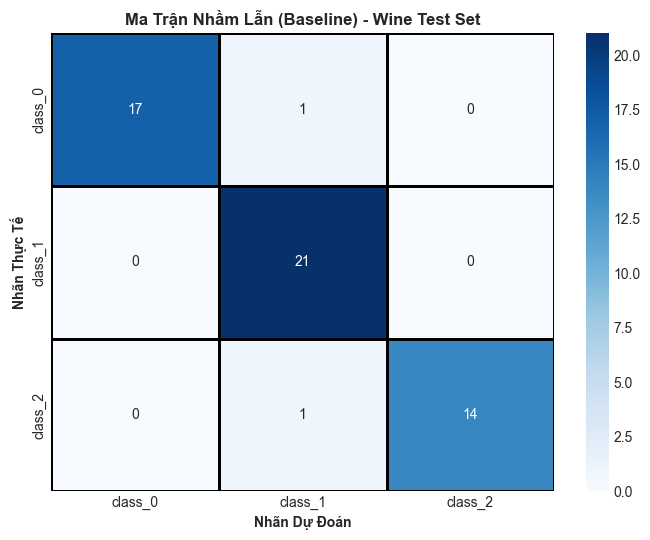

In [7]:
y_pred_base = clf_base.predict(X_test_scaled)
base_test_acc = accuracy_score(y_test, y_pred_base)
base_f1_weighted = f1_score(y_test, y_pred_base, average='weighted')
base_f1_macro = f1_score(y_test, y_pred_base, average='macro')
base_cm = confusion_matrix(y_test, y_pred_base)

print("=== ĐÁNH GIÁ MÔ HÌNH MẶC ĐỊNH TRÊN TẬP TEST ===")
print(f"1. Độ chính xác tập TRAIN:           {base_train_acc * 100:.2f}% ({base_train_acc:.4f})  <-- 100.00%")
print(f"2. Độ chính xác tập TEST (Accuracy): {base_test_acc * 100:.2f}% ({base_test_acc:.4f})")
print(f"3. Độ chênh lệch Train - Test:       {(base_train_acc - base_test_acc) * 100:.2f}%")
print(f"4. F1-Score Test (Weighted):         {base_f1_weighted * 100:.2f}% ({base_f1_weighted:.4f})")
print(f"5. F1-Score Test (Macro):            {base_f1_macro * 100:.2f}% ({base_f1_macro:.4f})")

print("\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT ===")
print(classification_report(y_test, y_pred_base, target_names=target_names, digits=4))

plt.figure(figsize=(7, 5.5))
sns.heatmap(base_cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, cbar=True, linewidths=1, linecolor='black')
plt.title("Ma Trận Nhầm Lẫn (Baseline) - Wine Test Set", fontweight='bold', fontsize=12)
plt.xlabel("Nhãn Dự Đoán", fontweight='bold')
plt.ylabel("Nhãn Thực Tế", fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Tinh chỉnh các tham số của cây quyết định với GridSearchCV để chọn tham số cho F-Score tốt nhất


In [8]:
param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': [2, 3, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print("\n=== KẾT QUẢ TINH CHỈNH THAM SỐ VỚI GRIDSEARCHCV TRÊN WINE DATASET ===")
print("Bộ tham số tối ưu nhất cho F-Score cao nhất:")
for param, val in grid_search.best_params_.items():
    print(f"   - {param:<20}: {val}")

print(f"\nĐiểm F1-Score trung bình cao nhất qua 5-Fold CV: {grid_search.best_score_ * 100:.2f}% ({grid_search.best_score_:.4f})")


Fitting 5 folds for each of 360 candidates, totalling 1800 fits



=== KẾT QUẢ TINH CHỈNH THAM SỐ VỚI GRIDSEARCHCV TRÊN WINE DATASET ===
Bộ tham số tối ưu nhất cho F-Score cao nhất:
   - criterion           : gini
   - max_depth           : 3
   - min_samples_leaf    : 3
   - min_samples_split   : 2

Điểm F1-Score trung bình cao nhất qua 5-Fold CV: 89.30% (0.8930)


## 8. Đánh giá mô hình tối ưu trên tập Test và So sánh hiệu năng trước/sau tinh chỉnh


=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TINH CHỈNH TỐI ƯU TRÊN TẬP TEST ===
1. Độ chính xác tập TRAIN:           96.77% (0.9677)
2. Độ chính xác tập TEST (Accuracy): 96.30% (0.9630)
3. Độ chênh lệch Train - Test:       0.48%       <-- Thu hẹp khoảng cách!
4. F1-Score Test (Weighted):         96.27% (0.9627)
5. F1-Score Test (Macro):            96.52% (0.9652)

=== BÁO CÁO PHÂN LOẠI CHI TIẾT ===
              precision    recall  f1-score   support

     class_0     1.0000    0.8889    0.9412        18
     class_1     0.9130    1.0000    0.9545        21
     class_2     1.0000    1.0000    1.0000        15

    accuracy                         0.9630        54
   macro avg     0.9710    0.9630    0.9652        54
weighted avg     0.9662    0.9630    0.9627        54



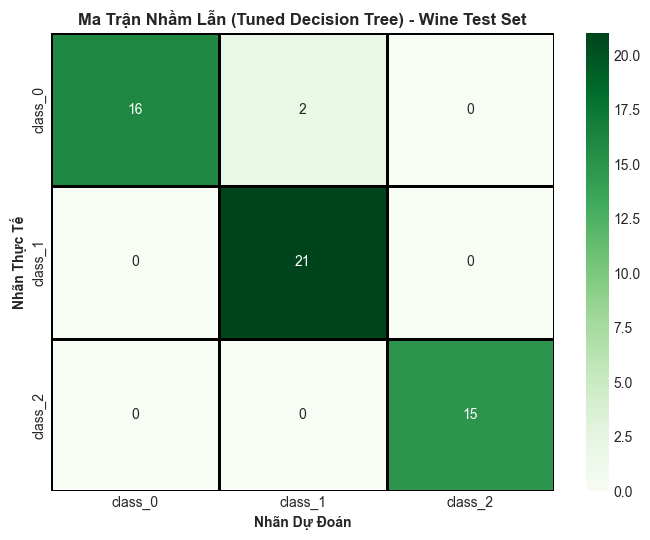


=== BẢNG SO SÁNH HIỆU NĂNG TRƯỚC VÀ SAU KHI TINH CHỈNH (WINE DATASET) ===
                                     Tiêu chí Mô hình Mặc định (Baseline) Mô hình Tối ưu (GridSearchCV)
             Tiêu chuẩn phân chia (criterion)                        gini                          gini
                   Độ sâu của cây (max_depth)                           4                             3
Số mẫu tối thiểu chia nút (min_samples_split)                           2                             2
   Số mẫu tối thiểu nút lá (min_samples_leaf)                           1                             3
                Tổng số nút lá (leaves count)                           8                             6
           Độ chính xác tập Train (Train Acc)                     100.00%                        96.77%
             Độ chính xác tập Test (Test Acc)                      96.30%                        96.30%
             Độ chênh lệch Train - Test (Gap)                       3.70%                0.48

In [9]:
best_model = grid_search.best_estimator_

best_train_acc = best_model.score(X_train_scaled, y_train)
y_pred_best = best_model.predict(X_test_scaled)

best_test_acc = accuracy_score(y_test, y_pred_best)
best_f1_weighted = f1_score(y_test, y_pred_best, average='weighted')
best_f1_macro = f1_score(y_test, y_pred_best, average='macro')
cm_best = confusion_matrix(y_test, y_pred_best)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TINH CHỈNH TỐI ƯU TRÊN TẬP TEST ===")
print(f"1. Độ chính xác tập TRAIN:           {best_train_acc * 100:.2f}% ({best_train_acc:.4f})")
print(f"2. Độ chính xác tập TEST (Accuracy): {best_test_acc * 100:.2f}% ({best_test_acc:.4f})")
print(f"3. Độ chênh lệch Train - Test:       {(best_train_acc - best_test_acc) * 100:.2f}%       <-- Thu hẹp khoảng cách!")
print(f"4. F1-Score Test (Weighted):         {best_f1_weighted * 100:.2f}% ({best_f1_weighted:.4f})")
print(f"5. F1-Score Test (Macro):            {best_f1_macro * 100:.2f}% ({best_f1_macro:.4f})")

print("\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT ===")
print(classification_report(y_test, y_pred_best, target_names=target_names, digits=4))

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names, cbar=True, linewidths=1, linecolor='black')
plt.title("Ma Trận Nhầm Lẫn (Tuned Decision Tree) - Wine Test Set", fontweight='bold', fontsize=12)
plt.xlabel("Nhãn Dự Đoán", fontweight='bold')
plt.ylabel("Nhãn Thực Tế", fontweight='bold')
plt.tight_layout()
plt.show()

comparison_data = {
    "Tiêu chí": [
        "Tiêu chuẩn phân chia (criterion)",
        "Độ sâu của cây (max_depth)",
        "Số mẫu tối thiểu chia nút (min_samples_split)",
        "Số mẫu tối thiểu nút lá (min_samples_leaf)",
        "Tổng số nút lá (leaves count)",
        "Độ chính xác tập Train (Train Acc)",
        "Độ chính xác tập Test (Test Acc)",
        "Độ chênh lệch Train - Test (Gap)",
        "F1-Score Test (Weighted)",
        "F1-Score Test (Macro)"
    ],
    "Mô hình Mặc định (Baseline)": [
        clf_base.criterion,
        str(clf_base.get_depth()),
        str(clf_base.min_samples_split),
        str(clf_base.min_samples_leaf),
        str(clf_base.get_n_leaves()),
        f"{base_train_acc * 100:.2f}%",
        f"{base_test_acc * 100:.2f}%",
        f"{(base_train_acc - base_test_acc) * 100:.2f}%",
        f"{base_f1_weighted * 100:.2f}%",
        f"{base_f1_macro * 100:.2f}%"
    ],
    "Mô hình Tối ưu (GridSearchCV)": [
        best_model.criterion,
        str(best_model.get_depth()),
        str(best_model.min_samples_split),
        str(best_model.min_samples_leaf),
        str(best_model.get_n_leaves()),
        f"{best_train_acc * 100:.2f}%",
        f"{best_test_acc * 100:.2f}%",
        f"{(best_train_acc - best_test_acc) * 100:.2f}% (Tối ưu)",
        f"{best_f1_weighted * 100:.2f}%",
        f"{best_f1_macro * 100:.2f}%"
    ]
}

df_compare = pd.DataFrame(comparison_data)
print("\n=== BẢNG SO SÁNH HIỆU NĂNG TRƯỚC VÀ SAU KHI TINH CHỈNH (WINE DATASET) ===")
print(df_compare.to_string(index=False))


## 9. Trực quan hóa cây quyết định đã được tinh chỉnh tối ưu (Matplotlib, Graphviz, Text Rules)


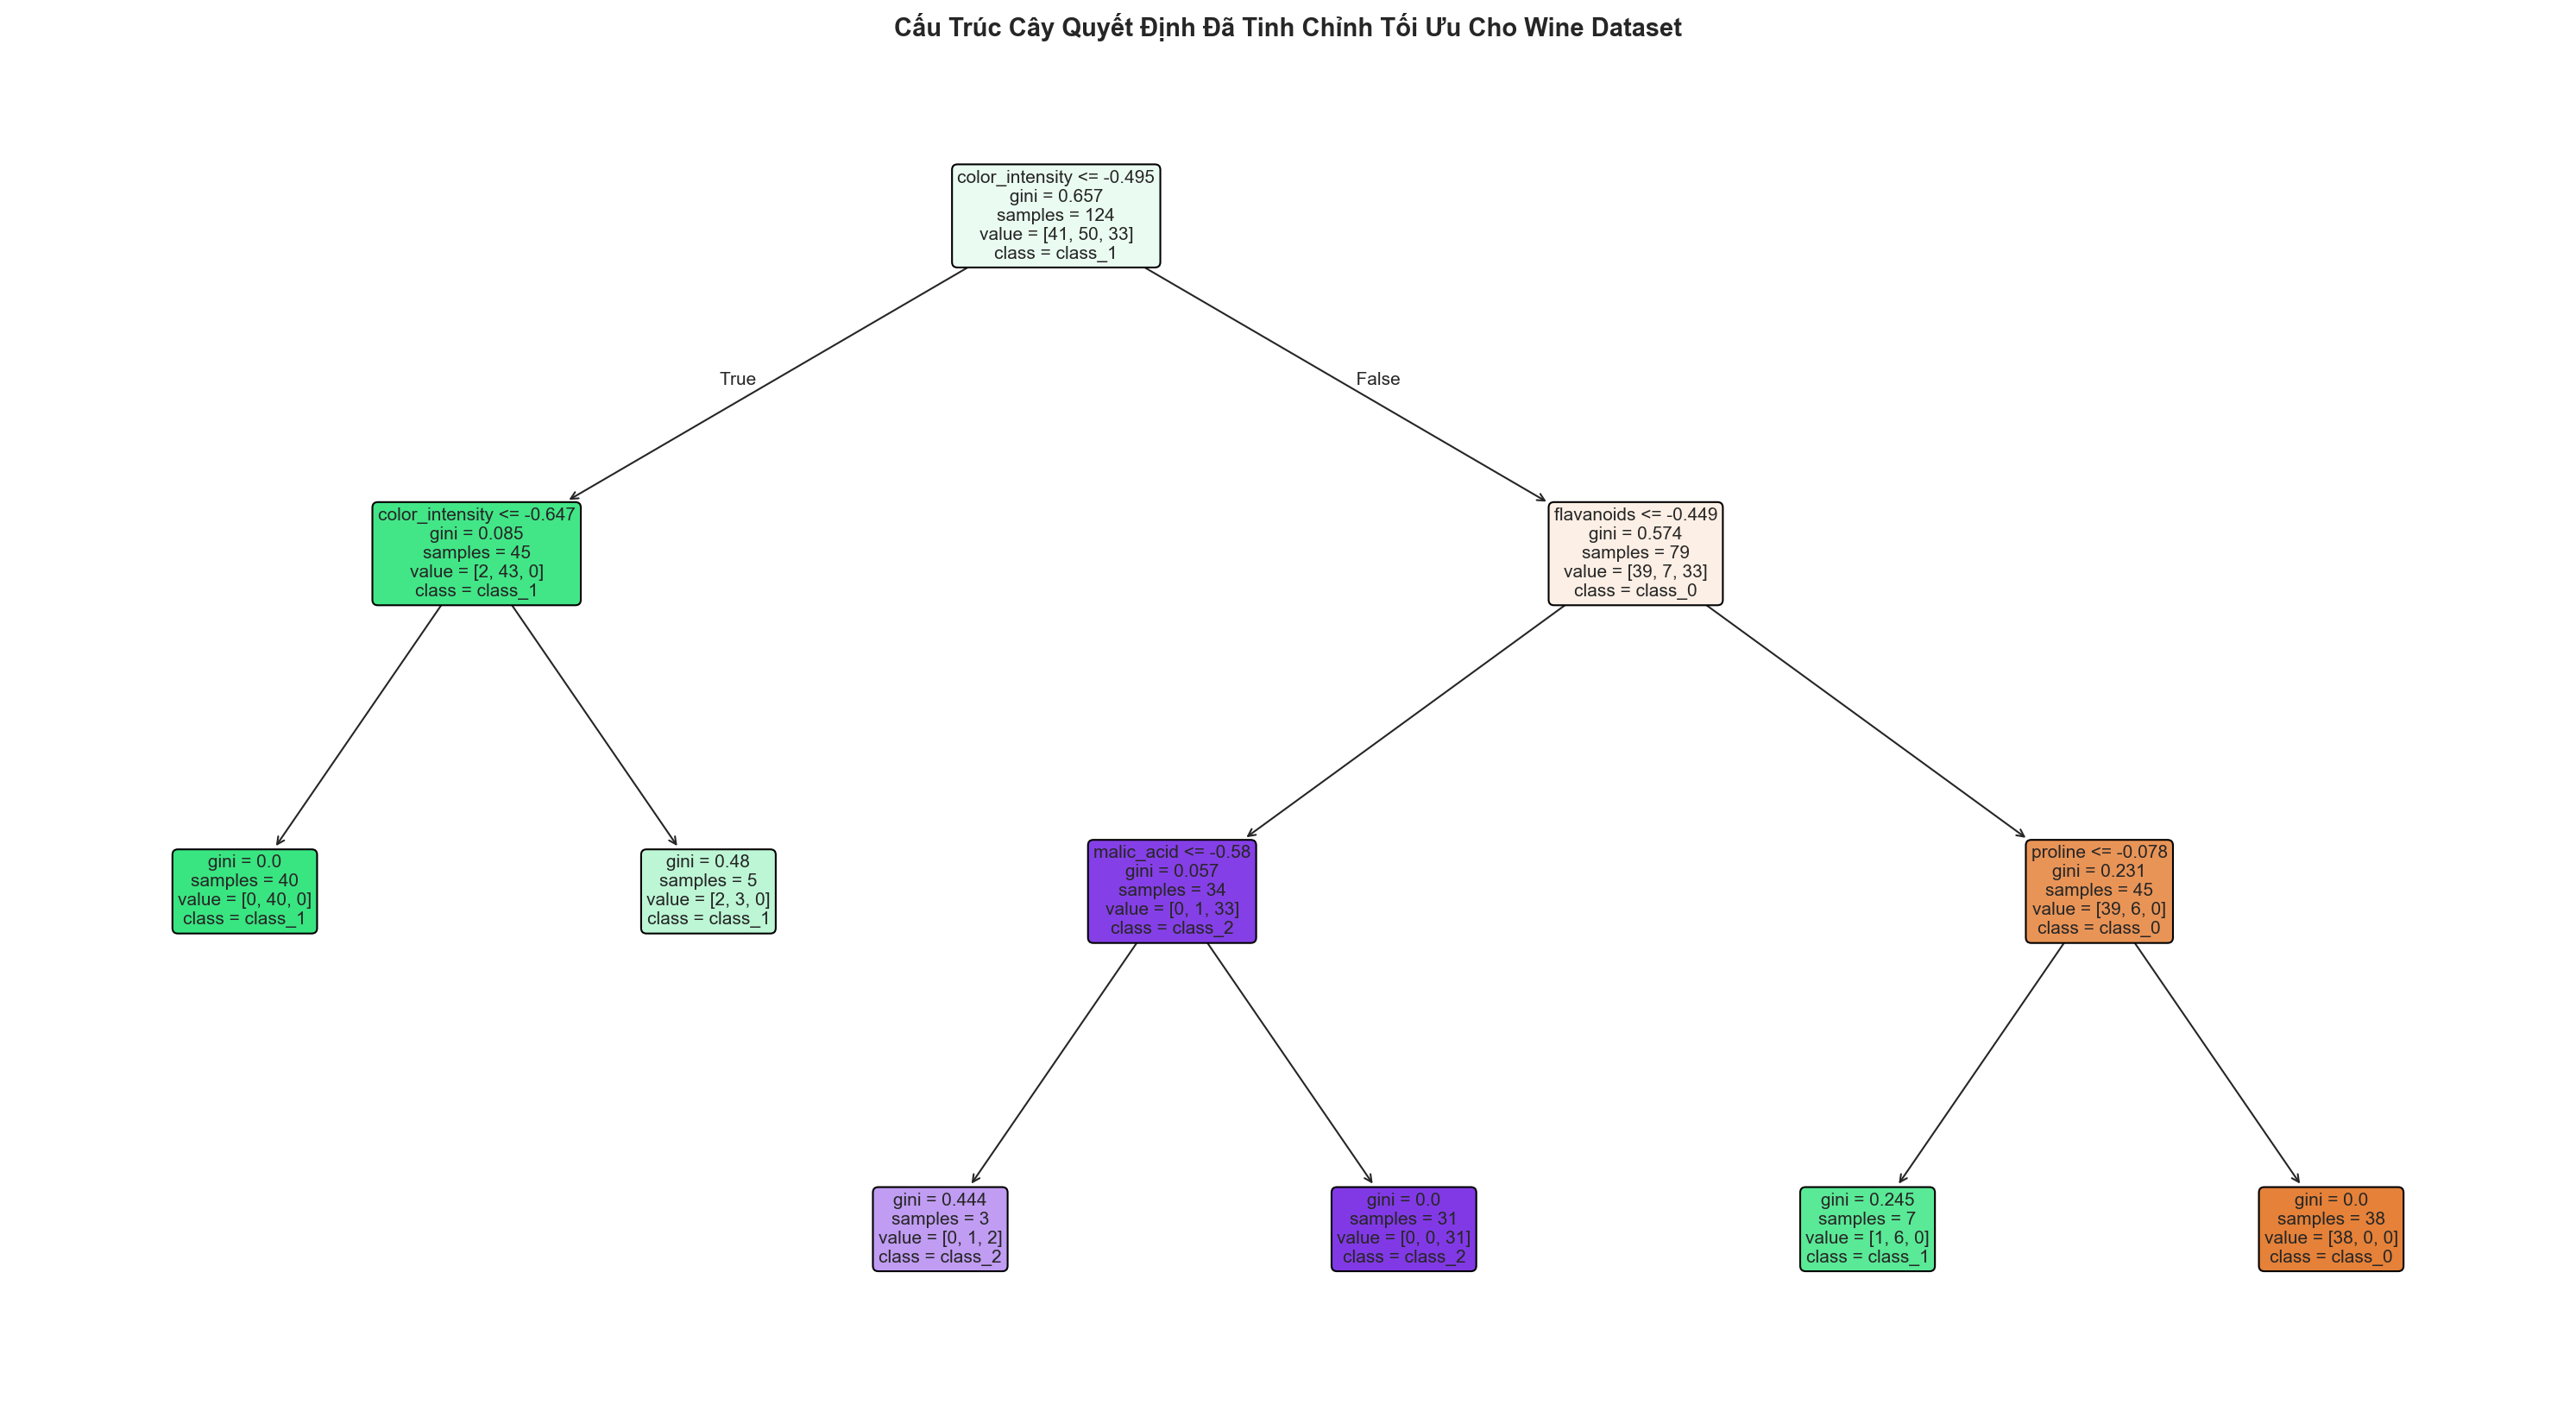

Đã xuất ảnh Graphviz 'wine_tuned_decision_tree.png'!

=== TẬP LUẬT QUYẾT ĐỊNH TỐI ƯU TRÊN WINE DATASET ===
|--- color_intensity <= -0.50
|   |--- color_intensity <= -0.65
|   |   |--- class: 1
|   |--- color_intensity >  -0.65
|   |   |--- class: 1
|--- color_intensity >  -0.50
|   |--- flavanoids <= -0.45
|   |   |--- malic_acid <= -0.58
|   |   |   |--- class: 2
|   |   |--- malic_acid >  -0.58
|   |   |   |--- class: 2
|   |--- flavanoids >  -0.45
|   |   |--- proline <= -0.08
|   |   |   |--- class: 1
|   |   |--- proline >  -0.08
|   |   |   |--- class: 0



In [10]:
plt.figure(figsize=(20, 11), dpi=150)
plot_tree(best_model, feature_names=feature_names, class_names=target_names, filled=True, rounded=True, fontsize=10)
plt.title("Cấu Trúc Cây Quyết Định Đã Tinh Chỉnh Tối Ưu Cho Wine Dataset", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

dot_data_wine = export_graphviz(best_model, out_file=None, feature_names=feature_names, class_names=target_names, filled=True, rounded=True)
try:
    graphviz.Source(dot_data_wine).render("wine_tuned_decision_tree", format="png", cleanup=True)
    print("Đã xuất ảnh Graphviz 'wine_tuned_decision_tree.png'!")
except Exception as e:
    print("Graphviz render notice:", e)

print("\n=== TẬP LUẬT QUYẾT ĐỊNH TỐI ƯU TRÊN WINE DATASET ===")
print(export_text(best_model, feature_names=list(feature_names)))
